# 04 - Euler's method, its error, and better methods

**MATH 331 - Differential Equations.** Lecture plan: Session 8 (preview of Euler's method) and Session 29 (numerical methods).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 1.7, Numerical methods: Euler's method**: Tables 1.7.1
  and 1.7.2; Exercises 1.7.1 and 1.7.2 **in the text** of the section; Exercises 1.7.4 and 1.7.9
  of the list at the end of the chapter (numerical instability; improved Euler).
* A. Meseguer, *Fundamentals of Numerical Mathematics for Physicists and Engineers* (Wiley, 2020),
  Section 8.2 (for the last part, "Going further").
* Related notebooks: 08 (computers compute approximately), 09 (slope fields), 13 (Euler's method
  on a falling body), 03E (optional). Video R09 (Taylor series); episode 3.

**What you will learn**
1. Euler's method, done by hand and then by the computer, on the example of the course text.
2. Why its error is proportional to the step $h$, and how to **measure** that.
3. Why better methods (Heun, Runge-Kutta) are worth their extra work.
4. Three ways a numerical answer can mislead: a solution that does not exist, a step that is too
   large, and rounding.

## 1. Theory in brief

**The problem.** $y' = f(x, y)$, $y(x_0) = y_0$. Most equations have no formula for the solution:
we compute it.

**Euler's method.** From the point $(x_i, y_i)$ follow the slope for a step $h$:

$$ \boxed{\;x_{i+1} = x_i + h, \qquad y_{i+1} = y_i + h\,f(x_i, y_i)\;} $$

It is the slope field of notebook 09, followed one segment at a time.

**Its error.** One step makes an error of about $\tfrac{h^2}{2}\,|y''|$ (the next term of the Taylor
series, video R09). To reach a fixed $x$ takes $(x - x_0)/h$ steps, so the errors add up to
something proportional to $h$: Euler's method is of **first order**. Halve the step, halve the
error; and do twice the work.

**Better methods.** Heun's method (improved Euler) uses two slopes per step and is of second
order: halve the step, the error is divided by 4. The classical Runge-Kutta method (RK4) uses
four slopes and is of fourth order: the error is divided by 16.

**How to trust a numerical answer.** Repeat with half the step: values that settle are evidence;
values that keep changing are a warning.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: euler, heun, rk4, observed_order, exponential_solution, logistic_solution, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. Euler's method by hand, then by the computer

The example of Lebl (Section 1.7): $\;y' = \dfrac{y^2}{3}$, $\;y(0) = 1$. Approximate $y(2)$.

Its exact solution is $y = \dfrac{3}{3 - x}$ (separable, notebook 10; it is Exercise 1.7.1 in the
text of the section), so $y(2) = 3$: we can see how wrong Euler's method is.

**By hand, with $h = 1$** (two steps):

* start: $x_0 = 0$, $y_0 = 1$; slope $f = 1^2/3 = 0.3333$;
* step 1: $y_1 = 1 + 1 \times 0.3333 = 1.3333$ at $x_1 = 1$; slope $1.3333^2/3 = 0.5926$;
* step 2: $y_2 = 1.3333 + 1 \times 0.5926 = 1.9259$ at $x_2 = 2$.

Euler says $y(2) \approx 1.926$; the truth is 3. A bad answer: the step is far too large. The
computer repeats the same recipe with as many steps as we like.

In [2]:
def f(x, y):
    return y ** 2 / 3


def exact(x):
    return 3 / (3 - x)


X_START, Y_START, X_END = 0.0, 1.0, 2.0

h = 1.0
x, y = X_START, Y_START
print(f"x = {x:.1f}   y = {y:.5f}")
while x < X_END:                               # the recipe, written out
    y = y + h * f(x, y)
    x = x + h
    print(f"x = {x:.1f}   y = {y:.5f}")
print(f"exact y(2) = {exact(X_END):.5f}")

grid, values = ol.euler(f, (X_START, X_END), Y_START, h)      # the same recipe, from the library
assert np.isclose(values[-1], y) and np.isclose(y, 1.92593, atol=1e-5)     # first row of Lebl's Table 1.7.1

x = 0.0   y = 1.00000
x = 1.0   y = 1.33333
x = 2.0   y = 1.92593
exact y(2) = 3.00000


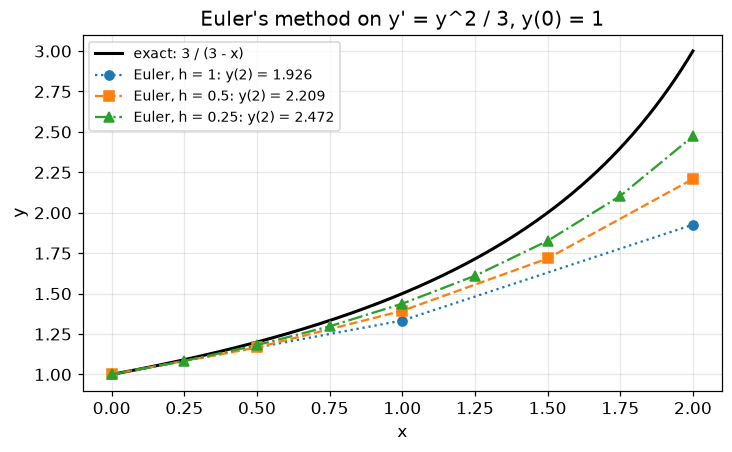

In [3]:
FIGURE_SIZE = (7.5, 4.2)
WIDE_FIGURE = (9.0, 3.8)
N_POINTS = 400
SHOWN_STEPS = (1.0, 0.5, 0.25)
MARKERS = ("o", "s", "^")
LINE_STYLES = (":", "--", "-.")

x_fine = np.linspace(X_START, X_END, N_POINTS)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(x_fine, exact(x_fine), "-", color="black", linewidth=2, label="exact: 3 / (3 - x)")
for step, marker, style in zip(SHOWN_STEPS, MARKERS, LINE_STYLES):
    grid, values = ol.euler(f, (X_START, X_END), Y_START, step)
    ax.plot(grid, values, marker=marker, linestyle=style, label=f"Euler, h = {step:g}: y(2) = {values[-1]:.3f}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Euler's method on y' = y^2 / 3, y(0) = 1")
ax.legend(loc="upper left")
plt.show()

*The plot shows* the exact solution (solid black curve), rising from 1 to 3 and bending upwards,
and three broken lines made of straight pieces: Euler's method with $h = 1$ (circles, two pieces),
$h = 0.5$ (squares, four pieces) and $h = 0.25$ (triangles, eight pieces). All three stay
**below** the curve, and get closer to it as the step gets smaller: at $x = 2$ they give 1.926,
2.209 and 2.472 against the exact 3.

Why below? Each piece follows the slope at its left end, and the true slope keeps growing along
the way.

## 3. Measuring the error: Lebl's Table 1.7.1

Halve the step again and again, and watch the error at $x = 2$. The table of the book is
reproduced to its five decimals.

*A note on the book.* For $h = 0.25$ the table prints 2.47250. Euler's method gives 2.472494,
which rounds to 2.47249; and the book's own error for that row, 0.52751, agrees with 2.472494.
The printed value is a small rounding slip. Checking every number is part of the job.

In [4]:
LEBL_TABLE_1_7_1 = (1.92593, 2.20861, 2.47250, 2.68034, 2.82040, 2.90412, 2.95035, 2.97472)
BOOK_DECIMALS = 1e-5

steps = [1 / 2 ** i for i in range(len(LEBL_TABLE_1_7_1))]
errors = []
print(f"{'h':>10} {'Euler y(2)':>12} {'Lebl':>9} {'error':>9} {'error / previous':>17}")
for step, book in zip(steps, LEBL_TABLE_1_7_1):
    value = ol.euler(f, (X_START, X_END), Y_START, step)[1][-1]
    errors.append(exact(X_END) - value)
    ratio = f"{errors[-1] / errors[-2]:17.5f}" if len(errors) > 1 else ""
    print(f"{step:10.7f} {value:12.6f} {book:9.5f} {errors[-1]:9.5f} {ratio}")
    assert abs(value - book) <= BOOK_DECIMALS             # agrees with the book to its five decimals

print("observed order:", np.round(ol.observed_order(errors), 2))

         h   Euler y(2)      Lebl     error  error / previous
 1.0000000     1.925926   1.92593   1.07407 
 0.5000000     2.208612   2.20861   0.79139           0.73681
 0.2500000     2.472494   2.47250   0.52751           0.66656
 0.1250000     2.680337   2.68034   0.31966           0.60599
 0.0625000     2.820401   2.82040   0.17960           0.56184
 0.0312500     2.904121   2.90412   0.09588           0.53385
 0.0156250     2.950355   2.95035   0.04965           0.51779
 0.0078125     2.974724   2.97472   0.02528           0.50913
observed order: [0.44 0.59 0.72 0.83 0.91 0.95 0.97]


Read the last column: each time the step is halved the error is multiplied by a number that
approaches $\tfrac12$. That is what **first order** means. The "observed order" in the last line
is the same information on a logarithmic scale: it approaches 1.

It also shows the price: the last row uses 256 steps and is still wrong in the second decimal.

## 4. Better methods: Heun and Runge-Kutta

**Heun's method** (improved Euler; Lebl, exercises of Section 1.7). Take an Euler step to guess
where you will land, compute the slope **there**, and go back and use the average of the two
slopes:

$$ k_1 = f(x_i, y_i), \qquad k_2 = f(x_i + h,\ y_i + h\,k_1), \qquad y_{i+1} = y_i + h\,\frac{k_1 + k_2}{2} . $$

**Runge-Kutta (RK4)** uses four slopes per step, with weights 1, 2, 2, 1 out of 6.

*Lebl, Exercise 1.7.9.* $\;y' = x + y$, $\;y(0) = 1$, with exact solution $y = 2e^x - x - 1$, so
$y(1) = 2e - 2 \approx 3.4366$. (The printed answer of the book says "$y(2)$ is approximately
3.4366": another small slip, 3.4366 is $y(1)$.)

In [5]:
def g(x, y):
    return x + y


TARGET = 2 * np.e - 2                       # the exact y(1)
METHODS = (("Euler", ol.euler), ("Heun", ol.heun), ("RK4", ol.rk4))
TWO_STEPS = (0.25, 0.125)

for name, method in METHODS:
    values = [method(g, (0.0, 1.0), 1.0, step)[1][-1] for step in TWO_STEPS]
    gaps = [TARGET - value for value in values]
    print(f"{name:5s}: y(1) = {values[0]:.4f} (h = 1/4), {values[1]:.4f} (h = 1/8);  "
          f"error multiplied by {gaps[1] / gaps[0]:.3f}")

# the answers printed in Lebl: improved Euler 3.3897 and 3.4237, Euler 2.8828 and 3.1316
assert abs(ol.heun(g, (0.0, 1.0), 1.0, 0.25)[1][-1] - 3.3897) < 1e-4
assert abs(ol.heun(g, (0.0, 1.0), 1.0, 0.125)[1][-1] - 3.4237) < 1e-4
assert abs(ol.euler(g, (0.0, 1.0), 1.0, 0.25)[1][-1] - 2.8828) < 1e-4
assert abs(ol.euler(g, (0.0, 1.0), 1.0, 0.125)[1][-1] - 3.1316) < 1e-4

Euler: y(1) = 2.8828 (h = 1/4), 3.1316 (h = 1/8);  error multiplied by 0.551
Heun : y(1) = 3.3897 (h = 1/4), 3.4237 (h = 1/8);  error multiplied by 0.275
RK4  : y(1) = 3.4364 (h = 1/4), 3.4366 (h = 1/8);  error multiplied by 0.069


Halving the step multiplies the error by about $\tfrac12$ for Euler, $\tfrac14$ for Heun and
$\tfrac1{16}$ for RK4. With eight steps RK4 already has five correct digits; Euler has one.

The picture for many steps, on logarithmic axes: a method of order $p$ gives a straight line of
slope $p$.

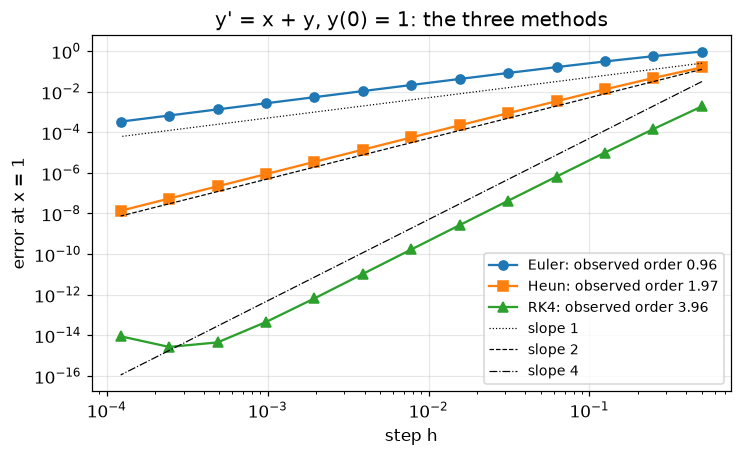

error of RK4 at the smallest step: 8.9e-15


In [6]:
HALVINGS = 13
FIRST_STEP = 0.5
ORDERS = (1, 2, 4)
GUIDE_STYLES = (":", "--", "-.")

many_steps = FIRST_STEP / 2.0 ** np.arange(HALVINGS)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
for (name, method), marker in zip(METHODS, MARKERS):
    gaps = np.array([abs(method(g, (0.0, 1.0), 1.0, step)[1][-1] - TARGET) for step in many_steps])
    order = ol.observed_order(gaps[:5])[-1]
    ax.loglog(many_steps, gaps, marker=marker, linestyle="-", label=f"{name}: observed order {order:.2f}")
for power, style in zip(ORDERS, GUIDE_STYLES):
    ax.loglog(many_steps, FIRST_STEP * many_steps ** power, linestyle=style, color="black", linewidth=0.8,
              label=f"slope {power}")
ax.set_xlabel("step h")
ax.set_ylabel("error at x = 1")
ax.set_title("y' = x + y, y(0) = 1: the three methods")
ax.legend(loc="lower right")
plt.show()

smallest = abs(ol.rk4(g, (0.0, 1.0), 1.0, many_steps[-1])[1][-1] - TARGET)
print(f"error of RK4 at the smallest step: {smallest:.1e}")

*The plot shows* three lines of markers on logarithmic axes, the error against the step: Euler
(circles) on top, Heun (squares) below it, RK4 (triangles) far below. Each is a straight line,
steeper for the better method; the thin black lines of slopes 1, 2 and 4 are there for
comparison. The lines of Euler and Heun go on down to the smallest step; the line of RK4 stops
going down near $10^{-14}$ and wanders there.

**The errors cannot decrease for ever.** That flat end of the RK4 line is **rounding**. The
computer keeps about 16 digits, and very small steps add rounding
errors instead of removing the error of the method (Lebl, end of Section 1.7; notebook 08,
Section 6).

## 5. When there is nothing to compute: Lebl's Table 1.7.2

For the same equation, $y' = y^2/3$, $y(0) = 1$, ask for $y(3)$. The exact solution
$y = 3/(3 - x)$ goes to infinity at $x = 3$: **there is no $y(3)$**. Euler's method does not know
it, and returns numbers all the same.

In [7]:
LEBL_TABLE_1_7_2 = (3.16232, 4.54329, 6.86079, 10.80321, 17.59893, 29.46004, 50.40121, 87.75769)
BEYOND = 3.0

for step, book in zip(steps, LEBL_TABLE_1_7_2):
    value = ol.euler(f, (X_START, BEYOND), Y_START, step)[1][-1]
    print(f"h = {step:9.7f}:  Euler's 'y(3)' = {value:10.5f}   (Lebl: {book:9.5f})")
    assert abs(value - book) < 1e-4

h = 1.0000000:  Euler's 'y(3)' =    3.16232   (Lebl:   3.16232)
h = 0.5000000:  Euler's 'y(3)' =    4.54329   (Lebl:   4.54329)
h = 0.2500000:  Euler's 'y(3)' =    6.86079   (Lebl:   6.86079)
h = 0.1250000:  Euler's 'y(3)' =   10.80321   (Lebl:  10.80321)
h = 0.0625000:  Euler's 'y(3)' =   17.59893   (Lebl:  17.59893)
h = 0.0312500:  Euler's 'y(3)' =   29.46004   (Lebl:  29.46004)
h = 0.0156250:  Euler's 'y(3)' =   50.40121   (Lebl:  50.40121)
h = 0.0078125:  Euler's 'y(3)' =   87.75769   (Lebl:  87.75769)


In Table 1.7.1 the numbers settled (2.90, 2.95, 2.97, ...). Here every halving of the step gives
a completely different number, larger and larger. **Numbers that settle are evidence that there
is something to compute; numbers that keep changing are a warning.**

## 6. A step that is too large

*Lebl, Exercise 1.7.4.* $\;y' = -5y$, $\;y(0) = 1$. The solution $e^{-5x}$ decays quietly to zero.
Euler's method gives $y_{i+1} = y_i - 5h\,y_i = (1 - 5h)\,y_i$: each step **multiplies** by
$1 - 5h$.

* $h < 0.2$: the factor is between 0 and 1: the values decay, as they should;
* $0.2 < h < 0.4$: the factor is between $-1$ and 0: the values decay, but **change sign at every
  step**. The true solution never does;
* $h > 0.4$: the factor is below $-1$: the values **grow**. Pure numerical nonsense.

It is what happened to the falling body of notebook 13: there the time constant was $\tau$, here
it is $\tfrac15$, and the thresholds are $h = \tau$ and $h = 2\tau$.

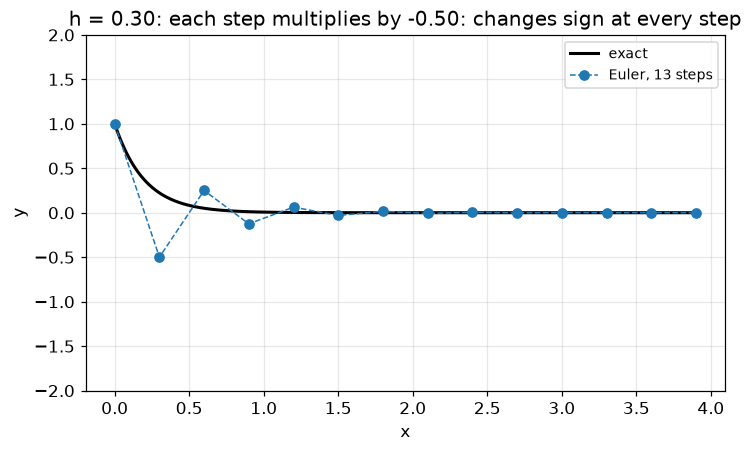

In [8]:
DECAY = 5.0                                 # the equation is y' = -DECAY * y
DEFAULT_STEP = 0.3
X_LONG = 4.0
Y_LIMITS = (-2.0, 2.0)


def plot_step(h=DEFAULT_STEP, x_end=X_LONG):
    # Euler's method on y' = -5 y against the exact solution, for one step size
    n_steps = max(1, int(round(x_end / h)))
    x_end = n_steps * h                        # a whole number of steps
    points = np.linspace(0.0, x_end, N_POINTS)
    factor = 1 - DECAY * h
    if factor >= 0:
        what = "decays, as it should"
    elif factor > -1:
        what = "changes sign at every step"
    elif factor == -1:
        what = "jumps between +1 and -1 for ever"
    else:
        what = "grows: nonsense"
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(points, np.exp(-DECAY * points), "-", color="black", linewidth=2, label="exact")
    try:
        grid, values = ol.euler(lambda xx, yy: -DECAY * yy, (0.0, x_end), 1.0, h)
        ax.plot(grid, values, "o--", linewidth=1, label=f"Euler, {n_steps} steps")
    except FloatingPointError:                 # the values ran away to infinity
        ax.plot([], [], " ", label="Euler: the values overflow")
    ax.set_ylim(*Y_LIMITS)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"h = {h:.2f}: each step multiplies by {factor:+.2f}: {what}")
    ax.legend(loc="upper right")
    plt.show()


plot_step()

*The plot shows* the exact solution (solid black), which falls from 1 to practically 0 before
$x = 1$, and Euler's values with $h = 0.3$ (circles joined by a dashed line): 1, then $-0.5$,
$0.25$, $-0.125$, ... They jump from one side of the axis to the other, with smaller and smaller
jumps.

**Slider.** Before moving it: at which value of $h$ do the jumps across the axis stop? At which
value do they start to grow instead of shrinking?

In [9]:
STEP_RANGE = (0.02, 0.6, 0.01)              # minimum, maximum, step
LENGTH_RANGE = (1.0, 10.0, 0.5)

interact(plot_step,
         h=FloatSlider(value=DEFAULT_STEP, min=STEP_RANGE[0], max=STEP_RANGE[1], step=STEP_RANGE[2],
                       description="h", continuous_update=False),
         x_end=FloatSlider(value=X_LONG, min=LENGTH_RANGE[0], max=LENGTH_RANGE[1], step=LENGTH_RANGE[2],
                           description="x max", continuous_update=False));

interactive(children=(FloatSlider(value=0.3, continuous_update=False, description='h', max=0.6, min=0.02, step...

(Below $h = 0.2$ there are no jumps; above $h = 0.4$ they grow.)

## 7. The three methods on the models of the course

For each model of notebooks 01-03 the exact solution is known, so the true error can be shown.
Choose the model and the number of steps.

**Before moving the slider:** on the logistic model, how many steps do you think Euler's method
needs to keep its largest error below 0.01? And RK4?

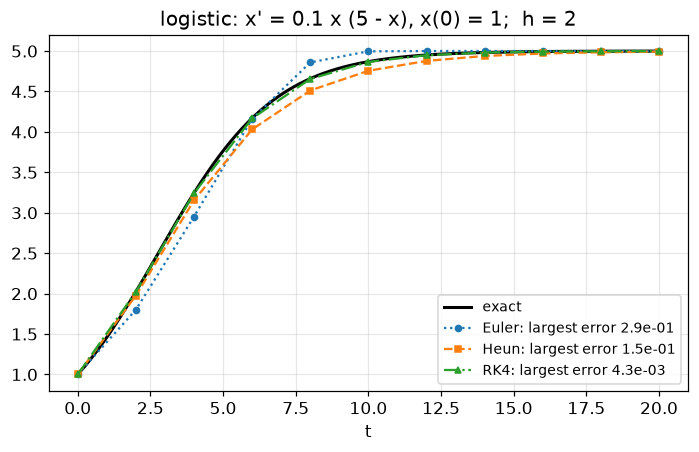

In [10]:
GROWTH_RATE = np.log(2) / 10                # the bacteria of notebook 01
MODELS = {
    "growth: P' = 0.0693 P, P(0) = 100": (lambda tt, yy: GROWTH_RATE * yy, 100.0, 60.0,
                                           lambda tt: ol.exponential_solution(tt, 100.0, GROWTH_RATE)),
    "decay: N' = -0.5 N, N(0) = 1": (lambda tt, yy: -0.5 * yy, 1.0, 10.0,
                                      lambda tt: ol.exponential_solution(tt, 1.0, -0.5)),
    "logistic: x' = 0.1 x (5 - x), x(0) = 1": (lambda tt, yy: 0.1 * yy * (5 - yy), 1.0, 20.0,
                                                lambda tt: ol.logistic_solution(tt, 1.0, 0.1, 5.0)),
}
LOGISTIC = list(MODELS)[2]
DEFAULT_COUNT = 10


def compare(model=LOGISTIC, n_steps=DEFAULT_COUNT):
    # Euler, Heun and RK4 with the same number of steps, against the exact solution
    rate, start, t_end, solution = MODELS[model]
    step = t_end / n_steps
    times = np.linspace(0.0, t_end, N_POINTS)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(times, solution(times), "-", color="black", linewidth=2, label="exact")
    for (name, method), marker, style in zip(METHODS, MARKERS, LINE_STYLES):
        grid, values = method(rate, (0.0, t_end), start, step)
        ax.plot(grid, values, marker=marker, linestyle=style, markersize=4,
                label=f"{name}: largest error {np.max(np.abs(values - solution(grid))):.1e}")
    ax.set_xlabel("t")
    ax.set_title(f"{model};  h = {step:.3g}")
    ax.legend(loc="lower right")
    plt.show()


compare()

In [11]:
COUNT_RANGE = (2, 300)

interact(compare, model=list(MODELS),
         n_steps=IntSlider(value=DEFAULT_COUNT, min=COUNT_RANGE[0], max=COUNT_RANGE[1], description="steps",
                           continuous_update=False));

interactive(children=(Dropdown(description='model', index=2, options=("growth: P' = 0.0693 P, P(0) = 100", "de...

*The static plot shows* the logistic model with 10 steps ($h = 2$): the exact S-shaped curve
(solid black) and the three methods. Euler (circles) is below the curve at first and above it
later; Heun (squares) stays a little below it; RK4 (triangles) is on it. The legend gives the
largest error of each along the way.

(On the logistic model Euler needs about 280 steps to keep its largest error below 0.01, Heun 37,
RK4 only 9. The error *at the end* would be a poor measure here: every method ends near the
equilibrium $x = 5$, whatever happened on the way.)

## 8. In practice: `solve_ivp`

A professional solver chooses the step by itself: it estimates the error of each step and makes
the step smaller or larger to keep that estimate below a **tolerance** that you give (`rtol`).
You have used it since notebook 08. The price of a smaller tolerance is more work:

In [12]:
TOLERANCES = (1e-3, 1e-6, 1e-9)
rate, start, t_end, solution = MODELS[LOGISTIC]

for tolerance in TOLERANCES:
    result = solve_ivp(rate, (0.0, t_end), [start], rtol=tolerance, atol=1e-12)
    gap = abs(result.y[0, -1] - solution(t_end))
    print(f"rtol = {tolerance:.0e}: {result.t.size:3d} points, {result.nfev:4d} evaluations of the slope, "
          f"error at the end {gap:.1e}")
    assert gap < 10 * tolerance * solution(t_end)

rtol = 1e-03:   9 points,   56 evaluations of the slope, error at the end 1.6e-04
rtol = 1e-06:  22 points,  140 evaluations of the slope, error at the end 4.9e-07
rtol = 1e-09:  71 points,  440 evaluations of the slope, error at the end 8.3e-10


## 9. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

Euler's method with $h = 1$ on $y' = y$, $y(0) = 1$.

* What value does it give for $y(3)$? (Do the three steps in your head.)
* Is it above or below the exact value $e^3 \approx 20.1$? Type `True` if it is **below**.

In [13]:
my_value = None
my_value_is_below = None        # True or False
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 1, value", my_value, ol.euler(lambda xx, yy: yy, (0.0, 3.0), 1.0, 1.0)[1][-1])
ol.check("Exercise 1, below", my_value_is_below, True);

Exercise 1, value: no answer yet (replace None with your value)
Exercise 1, below: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** For $y' = y^2/3$, $y(0) = 1$, do Euler's method by hand with $h = \tfrac12$ (four steps) and
give the approximation of $y(2)$, with three decimals. It is the second row of Lebl's table.

**(b)** *Lebl, Exercise 1.7.2 in the text.* Suppose you do not know the exact $y(2)$. From the
**last two** rows of Table 1.7.1 (2.95035 and 2.97472), and knowing that the error halves when
the step is halved, estimate the error of the last row. (If the error halves, the last error is
about equal to the difference of the last two values.)

**(c)** *Adapted from Lebl, Exercise 1.7.4.* For $y' = -5y$: below which $h$ do Euler's values keep their sign,
and below which $h$ do they decay? Type the two numbers in a list.

In [14]:
my_second_row = None            # (a)
my_error_estimate = None        # (b)
my_thresholds = None            # (c): [no change of sign below, decay below]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

THREE_DECIMALS = 5e-4
ol.check("Exercise 2a", my_second_row, LEBL_TABLE_1_7_1[1], tol=THREE_DECIMALS)
if ol.check("Exercise 2b", my_error_estimate, LEBL_TABLE_1_7_1[-1] - LEBL_TABLE_1_7_1[-2], tol=THREE_DECIMALS):
    print(f"   (the true error of the last row is {errors[-1]:.5f}: the estimate is good)")
ol.check("Exercise 2c", my_thresholds, [1 / DECAY, 2 / DECAY]);

Exercise 2a: no answer yet (replace None with your value)
Exercise 2b: no answer yet (replace None with your value)
Exercise 2c: no answer yet (replace None with your value)


### Exercise 3 - Fill in

Complete the function `euler_step`: one step of Euler's method, from the point $(x, y)$ with step
$h$, for the equation $y' = f(x, y)$. It must return the new $y$. The next cell uses your step to
rebuild Lebl's Table 1.7.1 and compares it with the book.

In [15]:
def euler_step(f, x, y, h):
    return None                 # replace None with the formula

In [16]:
if euler_step(f, X_START, Y_START, 1.0) is None:
    print("Exercise 3: complete euler_step first")
else:
    for step, book in zip(steps, LEBL_TABLE_1_7_1):
        x_now, y_now = X_START, Y_START
        for _ in range(int(round((X_END - X_START) / step))):
            y_now = euler_step(f, x_now, y_now, step)
            x_now = x_now + step
        assert abs(y_now - book) <= BOOK_DECIMALS, f"with h = {step:g} your step gives {y_now:.5f}, the book {book:.5f}"
    # an equation whose slope depends on x too: Lebl, Exercise 1.7.9, four steps of 1/4
    x_now, y_now = 0.0, 1.0
    for _ in range(4):
        y_now = euler_step(g, x_now, y_now, TWO_STEPS[0])
        x_now = x_now + TWO_STEPS[0]
    assert abs(y_now - 2.8828) < 1e-4, "for y' = x + y the slope must be taken at the start of the step, (x, y)"
    print(f"Exercise 3: correct, all {len(steps)} rows of Lebl's Table 1.7.1")

Exercise 3: complete euler_step first


### Exercise 4 - Explore

For $P' = kP$ (notebook 01) Euler's method gives $P_{i+1} = (1 + hk)\,P_i$, so after $n$ steps
$P_n = (1 + hk)^n P_0$.

* With $k = 1$, $P_0 = 1$ and $t = 1$ ($n = 1/h$ steps), compute $(1 + h)^{1/h}$ for
  $h = 0.1, 0.01, 0.001$. Which famous number does it approach? How fast (what is the order)?
* For growth ($k > 0$), is Euler's value always below the exact one? Why? (Compare $1 + hk$ with
  $e^{hk}$: Taylor series, video R09.)
* Use the slider of Section 7 on the growth model to see it.

In [17]:
# your code here: for example (1 + 0.1) ** (1 / 0.1)

## 10. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. $1 \to 2 \to 4 \to 8$: Euler gives 8, **below** $e^3 = 20.1$ (`True`): the slope keeps growing
   during each step and Euler uses the slope at the start.
2. (a) $1 \to 1.1667 \to 1.3935 \to 1.7172 \to 2.2086$: $y(2) \approx 2.209$. (b) About
   $2.97472 - 2.95035 = 0.024$ (the true error is 0.025). (c) `[0.2, 0.4]`.
3. `return y + h * f(x, y)`
4. $2.5937$, $2.7048$, $2.7169$: the number $e = 2.71828...$, with an error proportional to $h$
   (first order). Yes: $e^{hk} = 1 + hk + \tfrac{(hk)^2}{2} + \dots > 1 + hk$, so each step falls a
   little short.

</details>

**Where to go next:** notebook 13, Section 7 (Euler's method on a falling body), and, if you are
curious, the rest of this notebook.

---

# Going further (optional)

What follows goes beyond the preview of Session 8. It belongs to Session 29 and will move to
notebook 22 (numerical methods, part 2).

## A. A precise statement about Euler's error

Suppose $f$ is *Lipschitz* in $y$ with constant $L$ (that is,
$|f(x, y_1) - f(x, y_2)| \le L\,|y_1 - y_2|$) and $|y''| \le K$ on $[x_0, X]$. Then Euler's values
satisfy

$$ |y(x_n) - y_n| \;\le\; \frac{K\,h}{2L}\,\Big(e^{L\,(x_n - x_0)} - 1\Big) \qquad (x_0 \le x_n \le X) $$

(Meseguer, Section 8.2).

*Sketch of the proof.* Let $e_n = y(x_n) - y_n$. Taylor's theorem gives
$y(x_{n+1}) = y(x_n) + h\,f(x_n, y(x_n)) + \tfrac{h^2}{2}y''(\xi_n)$. Subtracting Euler's step,
$e_{n+1} = e_n + h\,[f(x_n, y(x_n)) - f(x_n, y_n)] + \tfrac{h^2}{2}y''(\xi_n)$, hence
$|e_{n+1}| \le (1 + hL)\,|e_n| + \tfrac{K h^2}{2}$. Since $e_0 = 0$, by induction
$|e_n| \le \tfrac{K h^2}{2}\sum_{j < n}(1 + hL)^j = \tfrac{K h}{2L}\big[(1 + hL)^n - 1\big]$, and
$(1 + hL)^n \le e^{nhL}$. $\square$

The bound is proportional to $h$ (first order), but it can grow **exponentially** with the length
of the interval.

## B. The region of absolute stability

Section 6 for a general constant: for the test equation $y' = \lambda\,y$ (here $\lambda$ may be a
complex number with negative real part; in Section 6, $\lambda = -5$), Euler's method multiplies by
$1 + h\lambda$ at each step. The values decay exactly when

$$ |1 + z| < 1, \qquad z = h\lambda : $$

a disk of radius 1 centred at $-1$ in the complex plane, the **region of absolute stability** of
Euler's method. For Heun's method the factor is $1 + z + \tfrac{z^2}{2}$, and the region is
$|1 + z + z^2/2| < 1$ (Meseguer, Section 8.2).

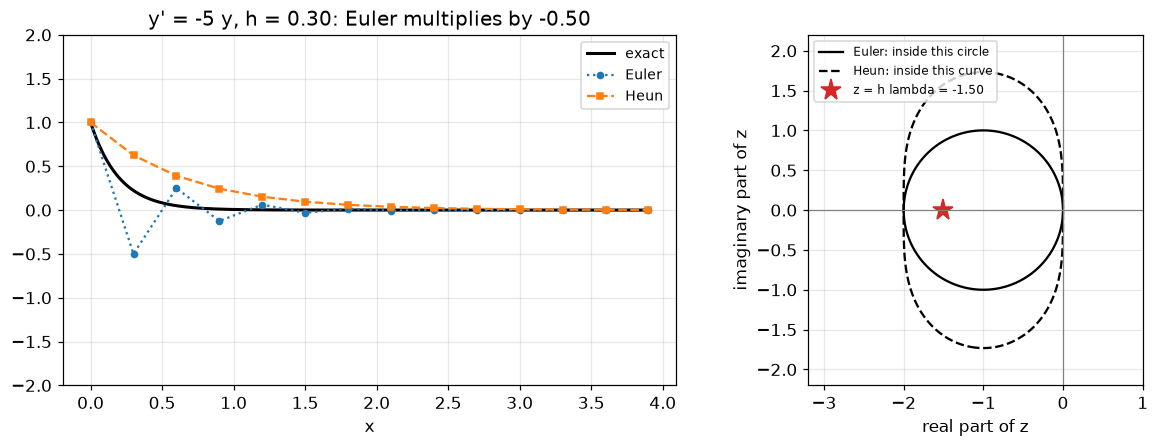

In [18]:
PLANE_X = (-3.2, 1.0)
PLANE_Y = (-2.2, 2.2)
GRID = 400
TWO_PANELS = (11.0, 4.2)
DEFAULT_RATE = -5.0


def plot_stability(h=DEFAULT_STEP, rate=DEFAULT_RATE, x_end=X_LONG):
    # Euler and Heun on y' = rate * y, and where z = h * rate lies with respect to the two regions
    n_steps = max(1, int(round(x_end / h)))
    x_end = n_steps * h
    points = np.linspace(0.0, x_end, N_POINTS)
    fig, (ax, plane) = plt.subplots(1, 2, figsize=TWO_PANELS, gridspec_kw={"width_ratios": (3, 2)})
    ax.plot(points, np.exp(rate * points), "-", color="black", linewidth=2, label="exact")
    for (name, method), marker, style in zip(METHODS[:2], MARKERS, LINE_STYLES):
        try:
            grid, values = method(lambda xx, yy: rate * yy, (0.0, x_end), 1.0, h)
            ax.plot(grid, values, marker=marker, linestyle=style, markersize=4, label=name)
        except FloatingPointError:
            ax.plot([], [], " ", label=f"{name}: the values overflow")
    ax.set_ylim(*Y_LIMITS)
    ax.set_xlabel("x")
    ax.set_title(f"y' = {rate:g} y, h = {h:.2f}: Euler multiplies by {1 + h * rate:+.2f}")
    ax.legend(loc="upper right")
    real, imaginary = np.meshgrid(np.linspace(*PLANE_X, GRID), np.linspace(*PLANE_Y, GRID))
    z = real + 1j * imaginary
    plane.contour(real, imaginary, np.abs(1 + z), levels=[1.0], colors="black", linestyles="-")
    plane.contour(real, imaginary, np.abs(1 + z + z ** 2 / 2), levels=[1.0], colors="black", linestyles="--")
    plane.plot([], [], "-", color="black", label="Euler: inside this circle")
    plane.plot([], [], "--", color="black", label="Heun: inside this curve")
    plane.plot(h * rate, 0.0, "*", color="tab:red", markersize=14, label=f"z = h lambda = {h * rate:.2f}")
    plane.axhline(0.0, color="gray", linewidth=0.8)
    plane.axvline(0.0, color="gray", linewidth=0.8)
    plane.set_aspect("equal")
    plane.set_xlabel("real part of z")
    plane.set_ylabel("imaginary part of z")
    plane.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()


plot_stability()

*The plot shows* two panels. Left: the exact solution of $y' = -5y$ (solid black) with Euler's
values (circles) and Heun's (squares) for $h = 0.3$; Euler's jump across the axis, Heun's decay
without changing sign. Right: the complex plane of $z = h\lambda$, with the circle inside which
Euler's method is stable (solid) and the larger, egg-shaped curve for Heun's method (dashed);
the red star is $z = -1.5$, inside both.

**Slider.** Before moving it: for $\lambda = -5$, at which $h$ does the star leave the circle?
Where does it leave Heun's curve (both curves cross the real axis at $z = -2$)?

In [19]:
RATE_RANGE = (-20.0, -0.5, 0.5)             # minimum, maximum, step

interact(plot_stability,
         h=FloatSlider(value=DEFAULT_STEP, min=STEP_RANGE[0], max=STEP_RANGE[1], step=STEP_RANGE[2],
                       description="h", continuous_update=False),
         rate=FloatSlider(value=DEFAULT_RATE, min=RATE_RANGE[0], max=RATE_RANGE[1], step=RATE_RANGE[2],
                          description="lambda", continuous_update=False),
         x_end=FloatSlider(value=X_LONG, min=LENGTH_RANGE[0], max=LENGTH_RANGE[1], step=LENGTH_RANGE[2],
                           description="x max", continuous_update=False));

interactive(children=(FloatSlider(value=0.3, continuous_update=False, description='h', max=0.6, min=0.02, step...

(At $h = 0.4$, where $z = -2$, for both methods.)

## C. Stiffness

A problem is **stiff** when stability, not accuracy, forces a very small step. In
$y' = -1000\,(y - \cos t)$ the solution follows $\cos t$ smoothly, but the constant 1000 keeps an
explicit method such as RK45 on tiny steps. An *implicit* method (`Radau`) has no such limit.

In [20]:
STIFFNESS = 1000.0
STIFF_TIME = 10.0
SOLVERS = ("RK45", "Radau")

counts = {}
for solver in SOLVERS:
    result = solve_ivp(lambda tt, yy: -STIFFNESS * (yy - np.cos(tt)), (0.0, STIFF_TIME), [0.0],
                       method=solver, rtol=1e-6)
    counts[solver] = result.t.size
    print(f"stiff problem with {solver:5s}: {result.t.size:5d} steps")
assert counts["RK45"] > 10 * counts["Radau"]

stiff problem with RK45 :  3277 steps
stiff problem with Radau:    69 steps


## Problems

Ordinary problems, without automatic checks.

1. Show that Heun's method is exact for $y' = 2x$ (any $h$). Is it exact for $y' = 3x^2$? Explain
   with the error of one step.
2. Show that Heun's method applied to $y' = \lambda y$ gives $y_{n+1} = (1 + z + z^2/2)\,y_n$ with
   $z = h\lambda$. For real $\lambda < 0$, find the interval of stability.
3. Prove that $(1 + hk)^{t/h} \to e^{kt}$ as $h \to 0^+$ (take logarithms and use
   $\ln(1 + u) = u - u^2/2 + \dots$). Conclude that Euler's method converges for $P' = kP$.
4. Apply Euler's method to the logistic equation $x' = 0.1\,x\,(5 - x)$, $x(0) = 1$, with
   $h = 25$. Compute the first four values by hand. What happens? (Notebook 03E, Section 3.)

<details>
<summary>Final answers (after trying)</summary>

1. Exact for $2x$; not for $3x^2$: one step has an error proportional to $h^3 y'''$, and
   $y''' = 0$ only in the first case.
2. $-2 < z < 0$.
4. $1,\ 11,\ -154,\ -61369$: the values run away to $-\infty$.

</details>